## Introducción

Como analista de datos, tu objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**. 
Para ello trabajarás con datos reales de TomTom Traffic Index y OECD Cities, que deberás limpiar, combinar y analizar para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [14]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [15]:
# cargar archivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

In [16]:
# mostrar las primeras 5 filas de traffic
traffic.head()

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [17]:
# mostrar las primeras 5 filas de eco
eco.head()

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


**Tip:** Si no usas `print()` la tabla se vera mejor.


---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspecciona su estructura, tipos de datos, columnas y valores faltantes.
Anota las columnas que necesiten limpieza y luego estandariza los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usa `.info()` para conocer la estructura de ambos DataFrames.
- Muestra los primeros 3 renglones de cada DF.
- Identifica si los detalles de cada DF estan bien o si requieren correcciones y escribe tus conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato ienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?


In [39]:
# Examinar la estructura de eco
eco.info()
eco.head(3)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     float64
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(5), int64(1), object(2)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,15.2,15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,29.5,22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,19.1,13.6,13600000.0


In [40]:
# Examinar la estructura de traffic
traffic.info()
traffic.head(3)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 13 columns):
 #   Column                           Non-Null Count    Dtype         
---  ------                           --------------    -----         
 0   country                          1004464 non-null  object        
 1   city                             1004464 non-null  object        
 2   update_time_utc                  1004464 non-null  datetime64[ns]
 3   jams_delay                       1004464 non-null  float64       
 4   traffic_index_live               1004464 non-null  float64       
 5   jams_length_kms                  1004464 non-null  float64       
 6   jams_count                       1004464 non-null  float64       
 7   traffic_index_week_ago           1004464 non-null  float64       
 8   update_time_utc_week_ago         1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10kms_mins  1004464 non-null  float64       
 10  travel_time_hist_per_10kms_min

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025



En la estructura del DF traffic, se observa que:

* Las columnas `UpdateTimeUTC` y `UpdateTimeUTCWeekAgo` son de tipo object (texto) y deberían ser datetime.
  
* La columna `JamsCount` es float64 y, al ser un conteo, podría ser int.

  
* No hay datos ausentes en ninguna columna.




En la estructura del DF eco, se observa que:

* Las columnas `City GDP/capita`, `Unemployment %`, `PM2.5 (μg/m³)` y `Population (M)` son de tipo object (texto) y deberían ser float64, porque traen separadores de miles, comas decimales o el símbolo %.
  
* No hay datos ausentes en ninguna columna.

### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifica que los cambios se hayan aplicado correctamente usando `.columns`.


In [20]:
# Estandarizar los nombres de las columnas de traffic
traffic = traffic.rename(columns={
    'Country': 'country',
    'City': 'city',
    'UpdateTimeUTC': 'update_time_utc',
    'JamsDelay': 'jams_delay',
    'TrafficIndexLive': 'traffic_index_live',
    'JamsLengthInKms': 'jams_length_in_kms',
    'JamsCount': 'jams_count',
    'TrafficIndexWeekAgo': 'traffic_index_week_ago',
    'UpdateTimeUTCWeekAgo': 'update_time_utc_week_ago',
    'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10kms_mins',
    'TravelTimeHistoricPer10KmsMins': 'travel_time_historic_per_10kms_mins',
    'MinsDelay': 'mins_delay'
})

# verificar cambios
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_in_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins',
       'travel_time_historic_per_10kms_mins', 'mins_delay'],
      dtype='object')

In [21]:
# Estandarizar los nombres de las columnas de eco
eco = eco.rename(columns={
    'Year': 'year',
    'City': 'city',
    'Country': 'country',
    'City GDP/capita': 'city_gdp_capita',
    'Unemployment %': 'unemployment_pct',
    'PM2.5 (μg/m³)': 'pm25',
    'Population (M)': 'population_m'
})

# verificar cambios
eco.columns

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m'],
      dtype='object')


### 2.3 Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.

**Instrucciones:**

- Convierte las columnas de fecha de `traffic` a formato `datetime`. Haz el cambio a prueba de errores.
- En el dataset `eco`, limpia los valores numéricos:
    - En `city_gdp_capita`: elimina separadores de miles (`.`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `unemployment_pct`: elimina el símbolo de porcentaje (`%`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `population_m`: reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
- Finalmente, crea una nueva columna llamada `population` multiplicando `population_m` por 1,000,000 para obtener la población total.


<details>
<summary>Haz clic para ver la pista</summary>
para eliminar símbolos, puedes reemplazarlos por un texto vacío.

In [22]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors='coerce')
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'], errors='coerce')

# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                               Non-Null Count    Dtype         
---  ------                               --------------    -----         
 0   country                              1004464 non-null  object        
 1   city                                 1004464 non-null  object        
 2   update_time_utc                      1004464 non-null  datetime64[ns]
 3   jams_delay                           1004464 non-null  float64       
 4   traffic_index_live                   1004464 non-null  float64       
 5   jams_length_in_kms                   1004464 non-null  float64       
 6   jams_count                           1004464 non-null  float64       
 7   traffic_index_week_ago               1004464 non-null  float64       
 8   update_time_utc_week_ago             1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10kms_mins      1004464 non-null  fl

In [24]:
# Limpiar valores numéricos de eco
eco['city_gdp_capita'] = (eco['city_gdp_capita']
                          .str.replace('.', '', regex=False)
                          .str.replace(',', '.', regex=False)
                          .astype(float))

eco['unemployment_pct'] = (eco['unemployment_pct']
                           .str.replace('%', '', regex=False)
                           .str.replace(',', '.', regex=False)
                           .astype(float))

eco['population_m'] = (eco['population_m']
                       .str.replace(',', '.', regex=False)
                       .astype(float))

# PM2.5 tiene el mismo problema de coma decimal
eco['pm25'] = eco['pm25'].str.replace(',', '.', regex=False).astype(float)

# Nueva columna: población total
eco['population'] = eco['population_m'] * 1_000_000

# verificar
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     float64
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(5), int64(1), object(2)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,15.2,15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,29.5,22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,19.1,13.6,13600000.0



---

## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [25]:
# Extraer el año de las fechas en update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year
# Verificar cambio
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [26]:
# Filtra los registros del año 2024
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()

# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,14.5,15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,28.0,22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,18.4,13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,12.8,4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,15.2,3.9,3900000.0


In [ ]:
# Validar que ambos DataFrames contienen únicamente registros de 2024
print(traffic_2024['year'].unique())
print(traffic_2024['year'].value_counts())
print(eco_2024['year'].unique())
print(eco_2024['year'].value_counts())


---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcularás los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupa los datos por `city`, `country` y `year`.
- Calcula el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guarda el resultado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


<details>
<summary>Haz clic para ver la pista</summary>
Usa ".agg()" para aplicar funciones de promedio. Al final, reinicia el índice para mantener las columnas de la agrupación como variables (no índices).

In [31]:
# Igualar los nombres de columnas con los de la plataforma
traffic_2024 = traffic_2024.rename(columns={
    'jams_length_in_kms': 'jams_length_kms',
    'travel_time_historic_per_10kms_mins': 'travel_time_hist_per_10kms_mins'
})

# Calcular los promedios de tráfico por ciudad, país y año
traffic_city_year_2024 = (traffic_2024
    .groupby(['city', 'country', 'year'])
    .agg({
        'jams_delay': 'mean',
        'traffic_index_live': 'mean',
        'jams_length_kms': 'mean',
        'jams_count': 'mean',
        'mins_delay': 'mean',
        'travel_time_live_per_10kms_mins': 'mean',
        'travel_time_hist_per_10kms_mins': 'mean'
    })
    .reset_index())

# Mostrar resultado
traffic_city_year_2024.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


In [44]:
traffic_city_year_2024.sort_values('jams_delay', ascending=False)
traffic_city_year_2024.sort_values('traffic_index_live', ascending=False).head(10)

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
156,istanbul,TUR,2024,1660.789019,45.614786,245.686252,411.145698,2.463699,19.982495,17.518796
66,bucharest,ROU,2024,607.273070,42.049003,73.736947,122.867736,2.314772,22.296033,19.981261
325,sharja,ARE,2024,411.378053,40.848230,64.414425,97.036726,1.262200,14.338117,13.075916
46,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
20,athens,GRC,2024,481.035798,35.756851,68.409656,123.210961,1.954033,19.528899,17.574866
110,dublin,IRL,2024,393.421923,35.443236,56.233449,97.956068,1.456989,17.605934,16.148945
303,rome,ITA,2024,499.419015,35.207433,89.814088,115.398012,1.457398,16.251666,14.794268
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550


# Conclusión del paso 4
El análisis de los indicadores de congestión vehicular muestra que **Mexico City** presenta el mayor tiempo promedio de retraso por tráfico (`jams_delay` ≈ 2.833 minutos), lo que la ubica como el caso más crítico de la muestra latinoamericana. Factores como la densidad urbana, la presión vehicular o la infraestructura vial no fueron medidos en este análisis, por lo que quedan como hipótesis para explorar posteriormente.

### 🧠 **Momento de reflexión**

¡Excelente trabajo hasta aquí!

Ahora que ya tienes los promedios anuales por ciudad, es momento de **observarlos** con atención.

Piensa:

- ¿Cuál crees que tiene el mayor tiempo promedio de tráfico?

Antes de revisar los datos, mi hipótesis era que la ciudad con mayor tiempo promedio de congestión sería una megaciudad asiática como Tokyo, o una metrópoli norteamericana como New York, por su tamaño poblacional y la extensión de su red vial. Como jams_delay acumula los minutos de retraso por embotellamientos, esperaba que las ciudades más grandes aparecieran primero.
- ¿Será una ciudad de **Europa**, de **Latinoamérica** o de **otra región** del mundo?

Al ordenar jams_delay de mayor a menor, la ciudad con mayor tiempo promedio de congestión en 2024 es Mexico City (≈ 2.833), una ciudad de Latinoamérica. Le siguen Tokyo (≈ 2.153), New York (≈ 2.133), London (≈ 2.051) y Manila (≈ 1.741), es decir, Asia, Norteamérica y Europa. Latinoamérica lidera el ranking, aunque en los primeros lugares hay ciudades de varias regiones.

Para descubrirlo, ejecuta esta línea de código:

`traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)`


🔍 Observa qué ciudad aparece en los primeros lugares.


¿Te sorprenden los resultados? , ¿Coinciden con lo que imaginabas?

Parcialmente. Esperaba que Mexico City estuviera entre las primeras posiciones, pero no que superara a Tokyo, New York y London por una diferencia tan amplia (≈ 2.833 frente a ≈ 2.153 de la segunda). Una posible explicación es que jams_delay es una métrica acumulada, por lo que favorece a las ciudades con mayor población y red vial. Por eso, para comparar la eficiencia por viaje, convendría complementar este análisis con mins_delay o traffic_index_live. Por ejemplo, Manila queda quinta en jams_delay, pero tiene un índice de tráfico muy alto (≈ 66), lo que indica una congestión intensa por viaje. Además, este ranking incluye las 387 ciudades de TomTom, no solo las 15 de Latinoamérica con las que se trabajará después.

Finalmente, al ordenar por traffic_index_live, el ranking cambia de forma notable. Mexico City baja del primer lugar (en jams_delay) al décimo, y Manila pasa a liderar con un índice de ≈ 66, muy por encima de Istanbul (≈ 46) y Bucharest (≈ 42). Esto confirma que jams_delay favorece a las megaciudades por su tamaño, mientras que traffic_index_live refleja mejor la intensidad de la congestión por viaje. Entre las ciudades latinoamericanas, Bogotá (≈ 37,6) supera a Mexico City (≈ 34,2) y Lima (≈ 31,0), lo que la convierte en un caso a observar en el análisis de inversión. La correlación moderada entre ambas métricas (≈ 0,62) sugiere que conviene usar las dos de forma complementaria.

In [32]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


La ciudad con el mayor tiempo promedio de tráfico es Mexico City (jams_delay ≈ 2.833), una ciudad de Latinoamérica.


---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets te permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Selecciona solo las **columnas relevantes** de cada dataset (por ejemplo, variables clave de tráfico y de economía).
- Usa `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Une ambos DataFrames y define como **claves de unión** a `city` y `year`.
- Mantén solo las ciudades y años presentes en ambos datasets.
- Guarda el resultado en una nueva variable llamada `merged` y muestra las primeras 5 filas.


<details>
<summary>Haz clic para ver la pista</summary>
Aplica una unión de tipo "inner" para mantener las ciudades y años presentes en ambos datasets.

In [33]:
# Seleccionar columnas clave de tráfico y economía
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_hist_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

# Usar .copy() para crear los dos nuevos datasets reducidos
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Unir datasets
merged = traffic_2024_small.merge(eco_2024_small, on=['city', 'year'], how='inner')

# Mostrar las primeras 5 filas
merged.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,16.8,6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,17.6,11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,12.8,4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,14.5,15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,13.5,3700000.0



---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que tienes un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos te ayudarán a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usa las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualiza la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualiza la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **compara ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Recuerda agregar título y etiquetas a los ejes de tus gráficos.
- Observa y comenta los patrones, valores extremos o posibles relaciones que identifiques.

**Tip:** Dentro de los parentesis del boxplot, agrega `showmeans=True` para ver la media en el gráfico.

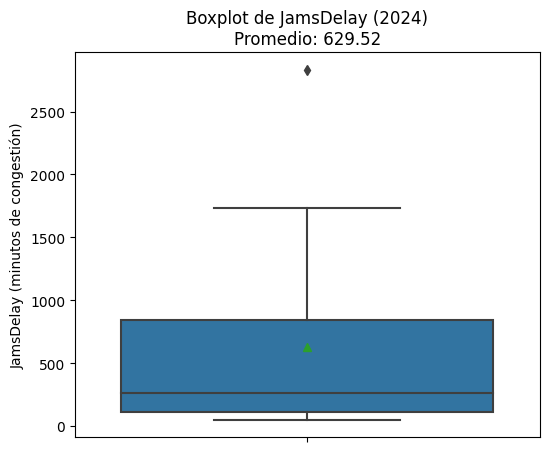

In [34]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
plt.figure(figsize=(6, 5))
sns.boxplot(y=merged['jams_delay'], showmeans=True)
plt.ylabel('JamsDelay (minutos de congestión)')

# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()


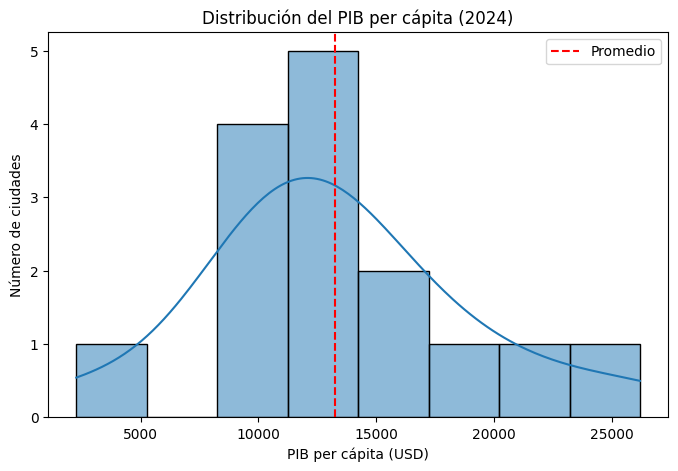

In [35]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
plt.figure(figsize=(8, 5))
sns.histplot(merged['city_gdp_capita'], bins=8, kde=True)
plt.axvline(merged['city_gdp_capita'].mean(), color='red', linestyle='--', label='Promedio')
plt.title('Distribución del PIB per cápita (2024)')
plt.xlabel('PIB per cápita (USD)')
plt.ylabel('Número de ciudades')
plt.legend()
plt.show()


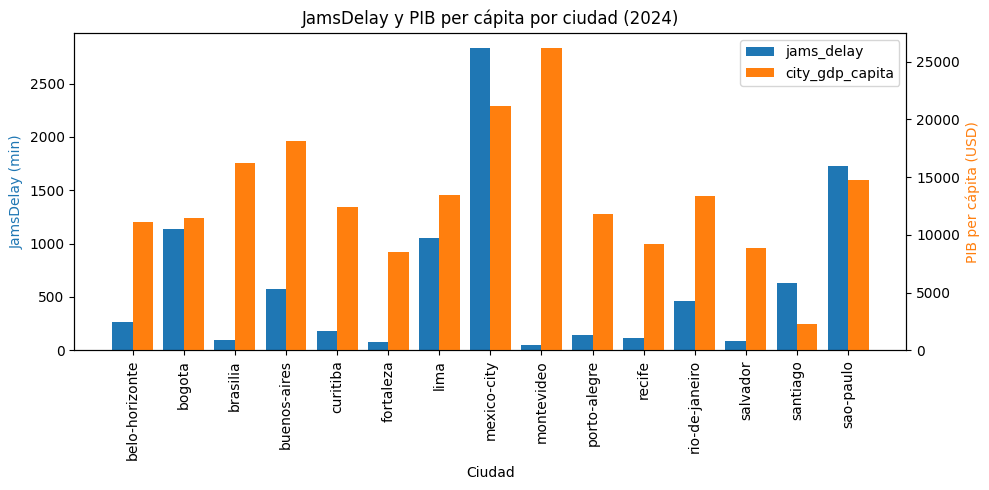

In [37]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()                      # segundo eje Y, a la derecha

x = np.arange(len(merged))             # posiciones de las ciudades
w = 0.4                                # ancho de cada barra

b1 = ax1.bar(x - w/2, merged['jams_delay'], w, color='tab:blue', label='jams_delay')
b2 = ax2.bar(x + w/2, merged['city_gdp_capita'], w, color='tab:orange', label='city_gdp_capita')

ax1.set_xticks(x)
ax1.set_xticklabels(merged['city'], rotation=90)
ax1.set_xlabel('Ciudad')
ax1.set_ylabel('JamsDelay (min)', color='tab:blue')
ax2.set_ylabel('PIB per cápita (USD)', color='tab:orange')
plt.title('JamsDelay y PIB per cápita por ciudad (2024)')
ax1.legend([b1, b2], ['jams_delay', 'city_gdp_capita'], loc='upper right')

plt.tight_layout()
plt.show()

**Tip:** Antes del `plt.show()` agrega el código `plt.xticks(rotation=90)` para rotar las etiquetas del eje X en 90 grados.

### 🧠 **Reflexiona**
Excelente trabajo llegando a esta etapa del análisis. Antes de avanzar, revisa tus gráficos, tómate un momento para pensar:

El boxplot muestra una distribución sesgada: el promedio de jams_delay (≈ 630) es muy superior a la mediana (≈ 263), y Mexico City aparece como valor atípico. El histograma del PIB per cápita se concentra en torno a los 13.000 USD, con Montevideo como valor alto y Santiago como valor extremo bajo.

* ¿Las ciudades con mayor PIB per cápita también presentan más congestión?

No de forma consistente. Entre las ciudades con mayor PIB per cápita, los niveles de congestión son muy distintos: Montevideo (≈ 26.176 USD) tiene un jams_delay de apenas ≈ 50 minutos, Buenos Aires (≈ 18.117 USD) tiene ≈ 571 y Mexico City (≈ 21.111 USD) tiene el valor más alto de la muestra, ≈ 2.833. Si un mayor PIB implicara más congestión, estas ciudades aparecerían juntas en la parte alta del ranking, y eso no ocurre. La correlación entre ambas variables es positiva pero débil (≈ 0,28), y con solo 15 ciudades no es estadísticamente significativa.

¿O sucede lo contrario, o no existe una relación clara?

No existe una relación clara, y tampoco se observa la relación inversa. Si mayor productividad significara menor congestión, las ciudades con PIB bajo concentrarían los valores altos de jams_delay, pero los datos muestran casos en ambos sentidos: Bogotá (≈ 11.442 USD) combina un PIB bajo con una congestión alta (≈ 1.142), mientras que Fortaleza (≈ 8.512 USD) y Salvador (≈ 8.899 USD) tienen PIB bajo y congestión muy baja (≈ 83 y ≈ 86). Además, São Paulo y Mexico City tienen PIB medio-alto y alta congestión. Dentro de esta muestra, la congestión acumulada muestra una asociación fuerte con la población (ρ de Spearman ≈ 0,86) y débil con el PIB per cápita (ρ ≈ 0,21). Esto no demuestra una causa: la infraestructura y la red vial son factores a investigar posteriormente. Por último, el PIB de Santiago (2.277 USD) parece un error de captura, por lo que conviene validarlo antes de sacar conclusiones definitivas.


Observación de calidad de datos: el PIB per cápita de Santiago en 2024 (2.277 USD) aparece así en el archivo original de OECD y es inconsistente con su valor de 2023 (22.176 USD) y con el resto de la muestra. Posiblemente se trate de un error de captura (dígito omitido). No se corrigió en el dataset final para mantener la trazabilidad con la fuente, por lo que Santiago aparece como valor atípico en los gráficos y debe interpretarse con cautela. Se recomienda validar el dato con la fuente antes de usarlo en decisiones de inversión.


---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa final consolidarás todo tu trabajo: guardarás el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exporta el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.


In [38]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)
check = pd.read_csv("ladb_mobility_economy_2024_clean.csv")
print(check.shape)
print(list(check.columns))
check.head(3)

(15, 14)
['city', 'country', 'year', 'jams_delay', 'traffic_index_live', 'jams_length_kms', 'jams_count', 'mins_delay', 'travel_time_live_per_10kms_mins', 'travel_time_hist_per_10kms_mins', 'city_gdp_capita', 'unemployment_pct', 'pm25', 'population']


,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,16.8,6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,17.6,11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,12.8,4800000.0


Para poder ver o descargar el archivo generado:   
En el menú lateral que esta a la izquierda, ve hasta la parte de abajo, a la sección de **Exportar dataset** para más información. 


---

## ✅ Entregables

1. **Notebook `.ipynb`** con todas las celdas (código + comentarios).
2. **CSV final**: `ladb_mobility_economy_2024_clean.csv`.
3. **Resumen ejecutivo breve** en Markdown (3–5 párrafos).


In [ ]:
# Cifras de apoyo para el resumen ejecutivo
print("Bogotá traffic_index_live:", round(merged.loc[merged['city'] == 'bogota', 'traffic_index_live'].iloc[0], 2))
print("Promedio de las 15 ciudades:", round(merged['traffic_index_live'].mean(), 2))
print("Ciudad con el índice más alto:", merged.loc[merged['traffic_index_live'].idxmax(), 'city'])
print("Mediana del PIB per cápita:", merged['city_gdp_capita'].median())
print("Spearman jams_delay vs población:", round(merged['jams_delay'].corr(merged['population'], method='spearman'), 2))
print("Spearman jams_delay vs PIB:", round(merged['jams_delay'].corr(merged['city_gdp_capita'], method='spearman'), 2))
print("Pearson jams_delay vs PIB:", round(merged['jams_delay'].corr(merged['city_gdp_capita']), 2))


---

# 🧾 Resumen ejecutivo

**Contexto, objetivo y cobertura**.
Este análisis busca responder si las ciudades más congestionadas de Latinoamérica son también las menos productivas. Para ello se compara la congestión (minutos de retraso por embotellamientos, índice de tráfico y tiempos de viaje) con el PIB per cápita, con el fin de priorizar dónde invertir en transporte. La muestra son 15 ciudades de 7 países en 2024, las únicas de las 387 de TomTom con datos económicos en la OECD; el tráfico cubre de octubre a diciembre.

**Metodología**. 
Se estandarizaron los nombres de columnas, se convirtieron las fechas y se limpió el formato numérico de la OECD. Luego se filtró 2024, se promedió el tráfico por ciudad y año, y se unió con los datos económicos mediante una unión INNER por city y year, que conserva solo las ciudades presentes en ambas fuentes. Las distribuciones y los valores atípicos se revisaron con un boxplot, un histograma y un gráfico de barras con doble eje.

**Hallazgos iniciales.**
No hay una relación clara entre congestión y PIB per cápita: la correlación es débil (≈ 0,28) y la muestra es pequeña. En esta muestra, la congestión se asocia más con la población (ρ ≈ 0,86) que con el ingreso (ρ ≈ 0,21); por ejemplo, Mexico City (≈ 21.111 USD, ≈ 2.833 min) y Montevideo (≈ 26.176 USD, ≈ 50 min) tienen un PIB alto pero una congestión muy distinta. Dos anomalías requieren revisión: el PIB de Santiago 2024 (2.277 USD) parece un error de captura de la fuente, y los datos de tráfico incluyen registros con índice superior a 100.

**Recomendaciones**. 
Bogotá registra un `traffic_index_live` de ≈ 37,61, el más alto de las 15 ciudades evaluadas (frente a un promedio muestral de ≈ 22,10), y un PIB per cápita (≈ 11.442 USD) por debajo de la mediana (≈ 12.381 USD). Por ello se recomienda focalizar las intervenciones de infraestructura y modelos de gestión de demanda en esta ciudad como caso prioritario de estudio en la región. Como la correlación entre congestión y PIB es débil, la priorización responde al perfil individual de la ciudad y no a una tendencia general.

